In [8]:
import os
print(os.listdir('/content'))

['.config', 'train-2.csv', 'sample_data']


Python libraries import.

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


CSV file load karna.

In [10]:
df = pd.read_csv('/content/train-2.csv')

print("Dataset loaded successfully!")

Dataset loaded successfully!


Checking the first 5 rows of data to undestand data .

In [ ]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Number of rows and coloumn in data.

In [11]:
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])


Total rows: 891
Total columns: 12


Checking on a coloumn name and data type.

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


To find descriptive statistics.

In [13]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


To check the missing values in column

In [14]:
print(df.isnull().sum().to_string())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2


To check for duplicate rows.

In [15]:
print("duplicate rows:",
      df.duplicated().sum())

duplicate rows: 0


To check the value of categorical columns.

In [16]:
for col in df.select_dtypes(include='object').columns:
    print(f"\nColumn: {col}")
    print(df[col].value_counts().head(10))


Column: Name
Name
Dooley, Mr. Patrick                                    1
Braund, Mr. Owen Harris                                1
Cumings, Mrs. John Bradley (Florence Briggs Thayer)    1
Heikkinen, Miss. Laina                                 1
Futrelle, Mrs. Jacques Heath (Lily May Peel)           1
Allen, Mr. William Henry                               1
Moran, Mr. James                                       1
McCarthy, Mr. Timothy J                                1
Palsson, Master. Gosta Leonard                         1
Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)      1
Name: count, dtype: int64

Column: Sex
Sex
male      577
female    314
Name: count, dtype: int64

Column: Ticket
Ticket
347082          7
1601            7
CA. 2343        7
3101295         6
CA 2144         6
347088          6
382652          5
S.O.C. 14879    5
113760          4
19950           4
Name: count, dtype: int64

Column: Cabin
Cabin
G6             4
C23 C25 C27    4
B96 B98        4
F2           

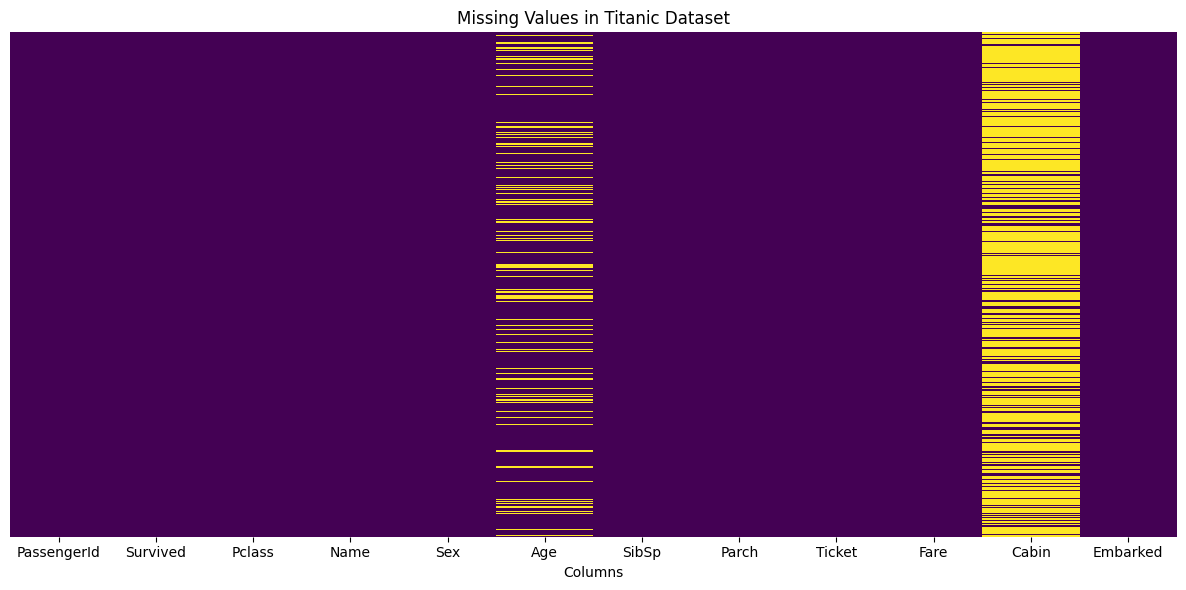

In [17]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap='viridis'
)

plt.title('Missing Values in Titanic Dataset')
plt.xlabel('Columns')
plt.tight_layout()
plt.show()

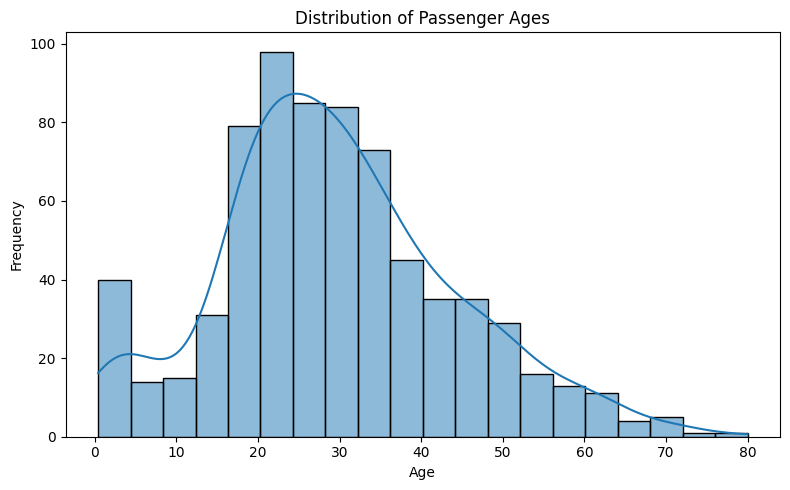

In [18]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='Age',
    bins=20,
    kde=True
)

plt.title('Distribution of Passenger Ages')
plt.xlabel('Age')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

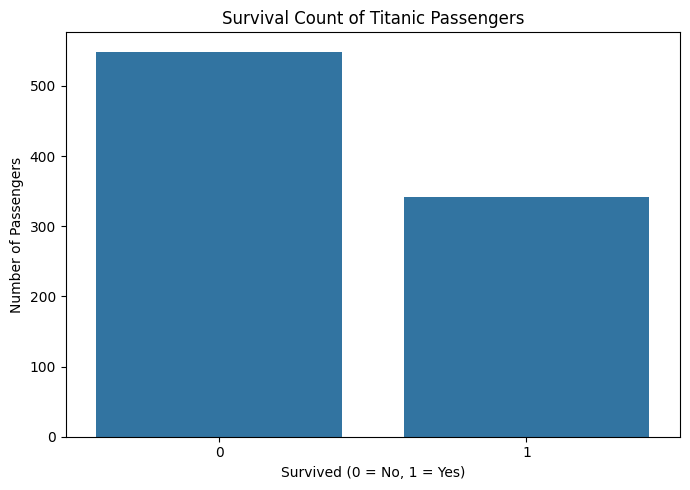

In [19]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='Survived'
)

plt.title('Survival Count of Titanic Passengers')
plt.xlabel('Survived (0 = No, 1 = Yes)')
plt.ylabel('Number of Passengers')

plt.tight_layout()
plt.show()

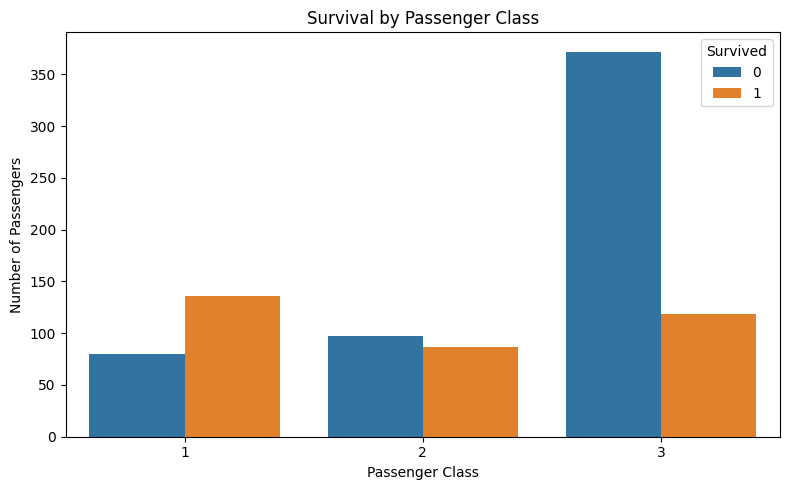

In [20]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Pclass',
    hue='Survived'
)

plt.title('Survival by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Number of Passengers')

plt.tight_layout()
plt.show()

Survival rate by passenger class:
Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64


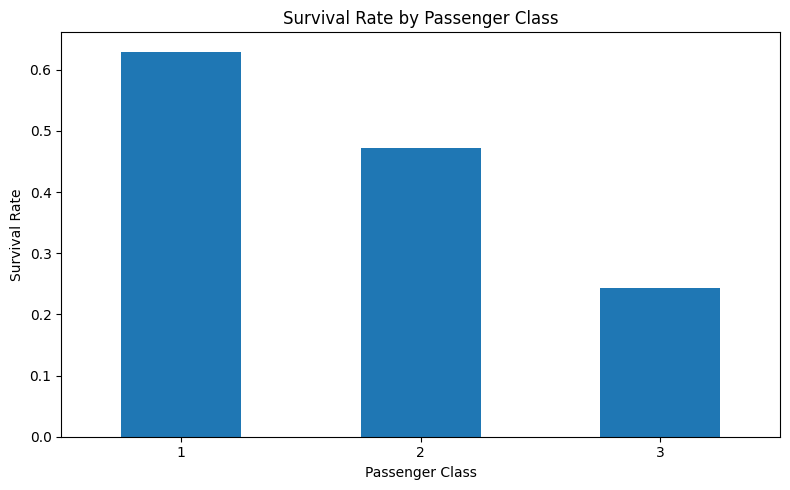

In [21]:
survival_by_class = df.groupby('Pclass')['Survived'].mean()

print("Survival rate by passenger class:")
print(survival_by_class)

plt.figure(figsize=(8, 5))

survival_by_class.plot(kind='bar')

plt.title('Survival Rate by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

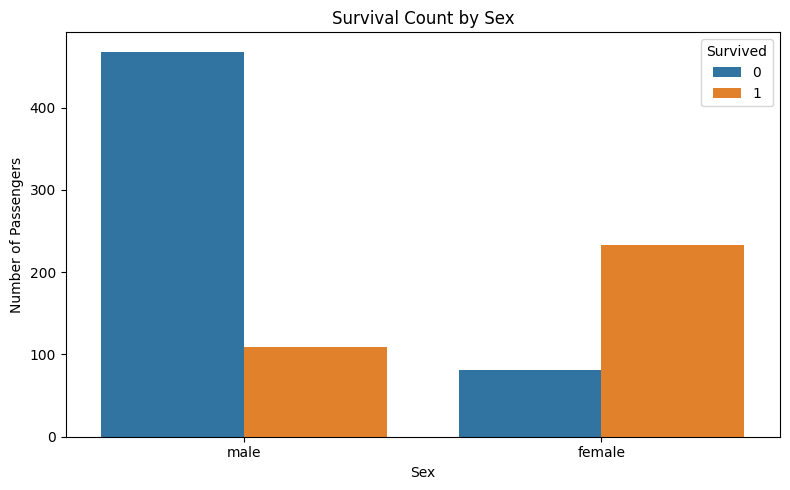

In [22]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Sex',
    hue='Survived'
)

plt.title('Survival Count by Sex')
plt.xlabel('Sex')
plt.ylabel('Number of Passengers')

plt.tight_layout()
plt.show()

Survival rate by sex:
Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64


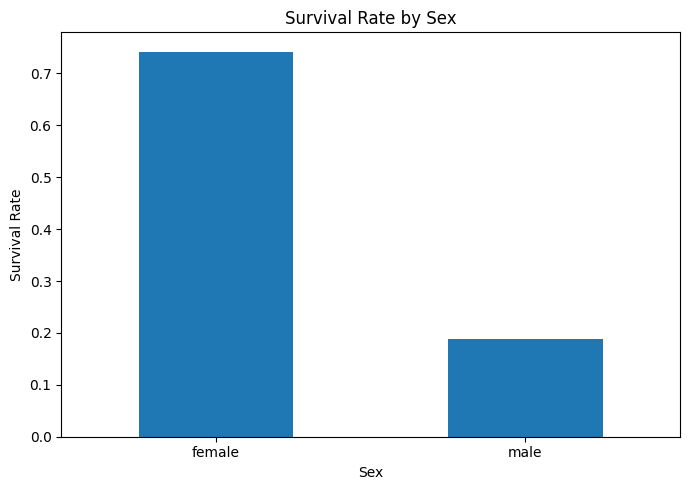

In [23]:
survival_by_sex = df.groupby('Sex')['Survived'].mean()

print("Survival rate by sex:")
print(survival_by_sex)

survival_by_sex.plot(kind='bar', figsize=(7, 5))

plt.title('Survival Rate by Sex')
plt.xlabel('Sex')
plt.ylabel('Survival Rate')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

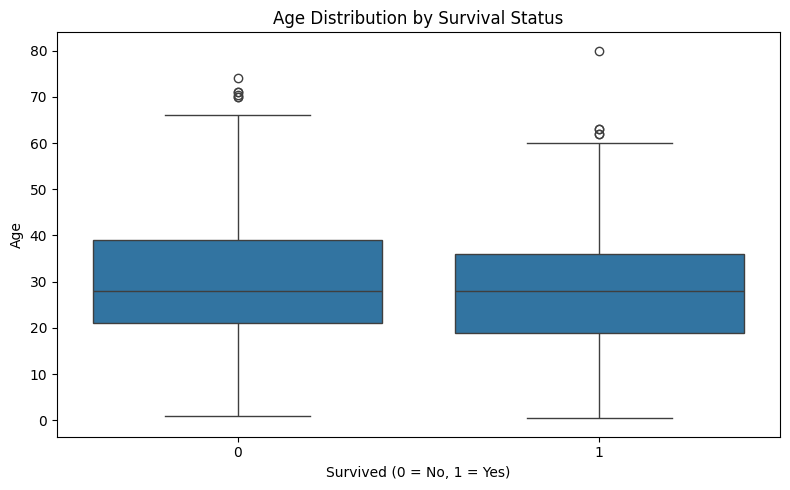

In [24]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='Survived',
    y='Age'
)

plt.title('Age Distribution by Survival Status')
plt.xlabel('Survived (0 = No, 1 = Yes)')
plt.ylabel('Age')

plt.tight_layout()
plt.show()

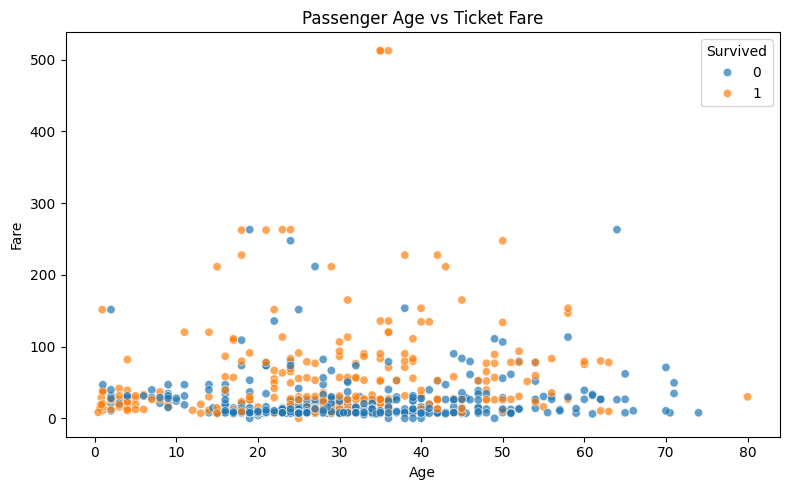

In [25]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Age',
    y='Fare',
    hue='Survived',
    alpha=0.7
)

plt.title('Passenger Age vs Ticket Fare')
plt.xlabel('Age')
plt.ylabel('Fare')

plt.tight_layout()
plt.show()

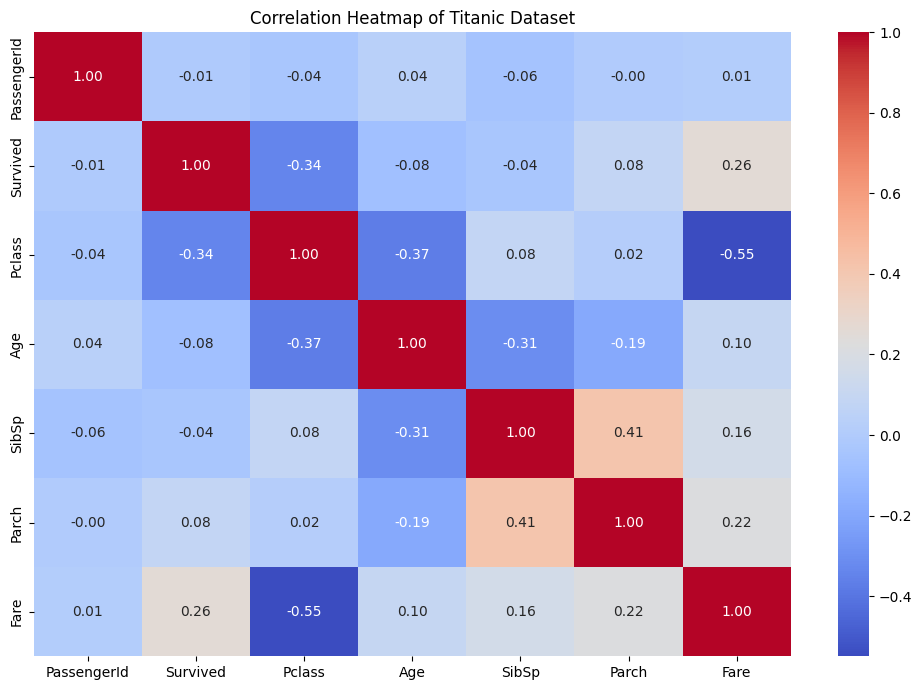

In [26]:
numeric_df = df.select_dtypes(include='number')

correlation_matrix = numeric_df.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Titanic Dataset')

plt.tight_layout()
plt.show()

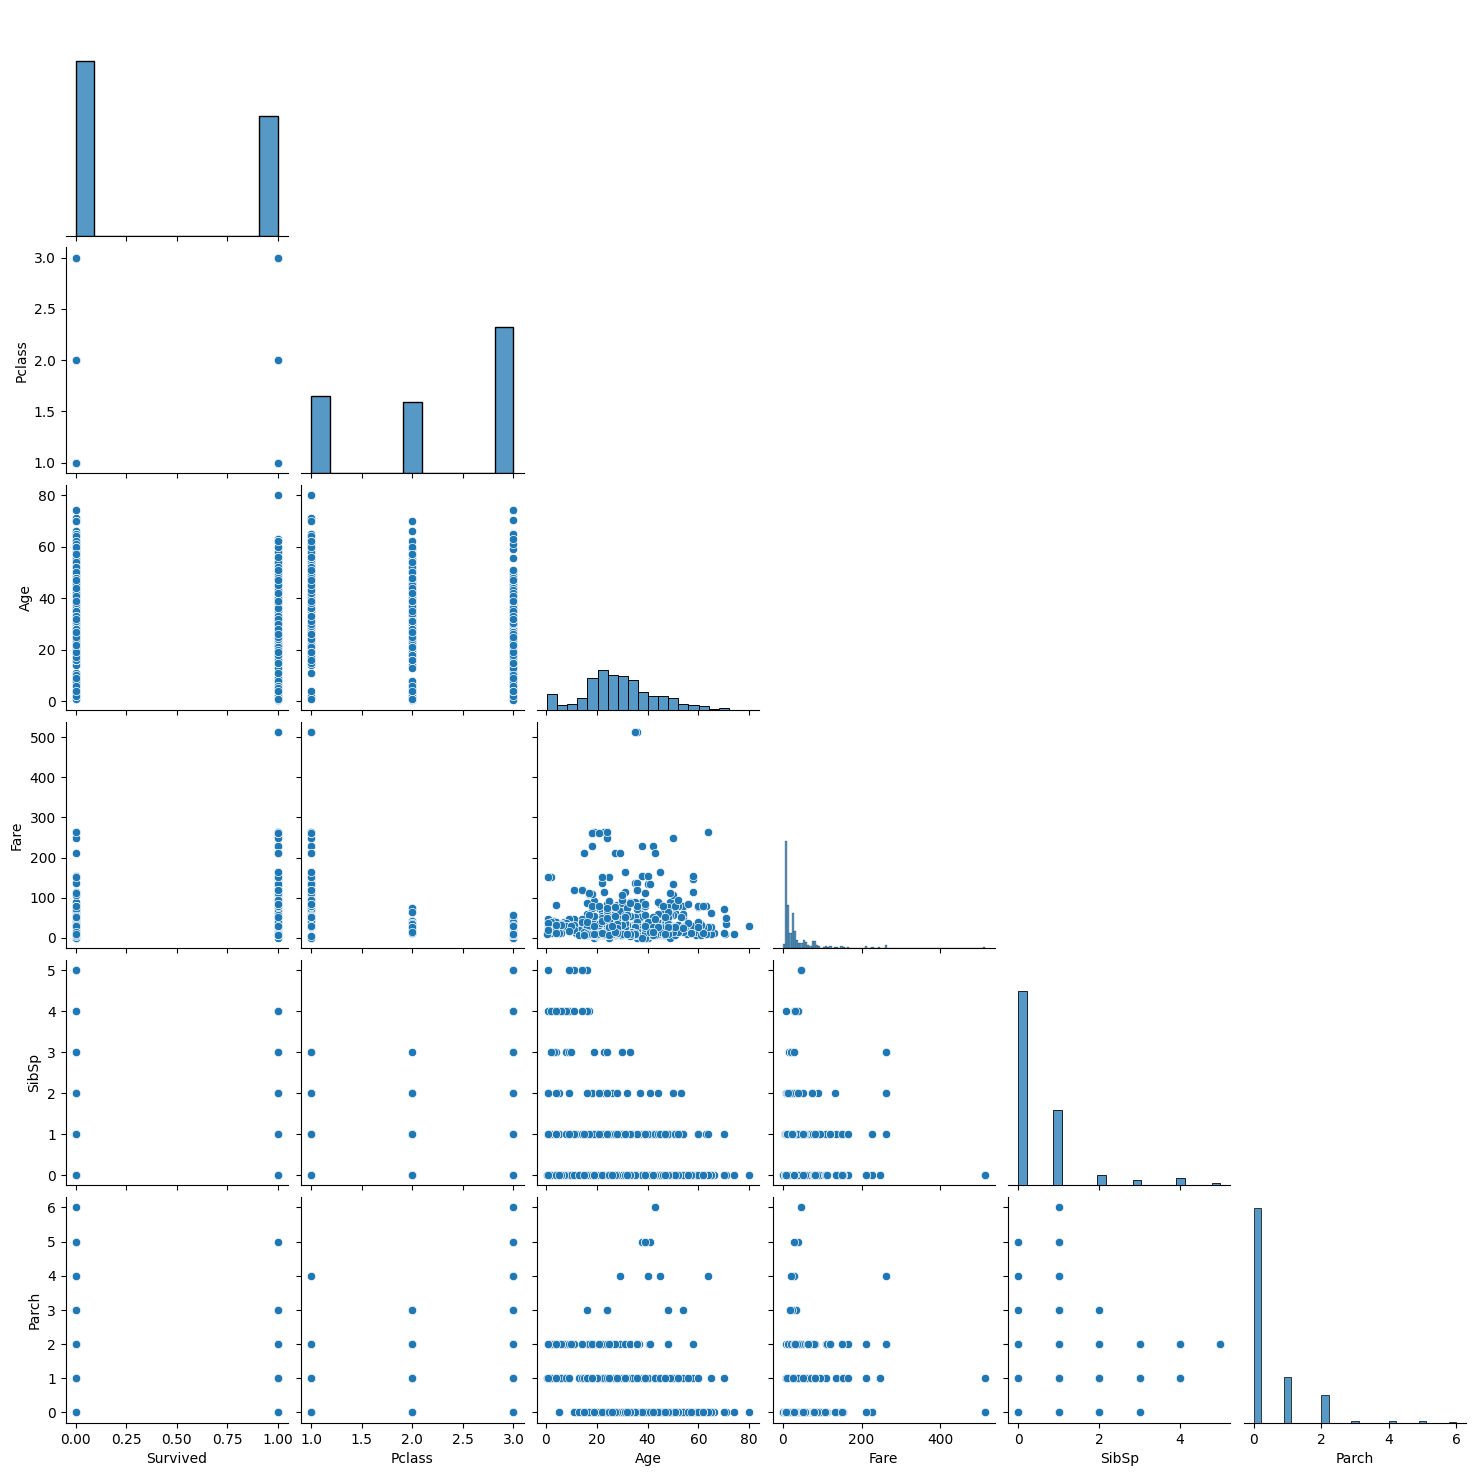

In [27]:
selected_columns = [
    'Survived',
    'Pclass',
    'Age',
    'Fare',
    'SibSp',
    'Parch'
]

pairplot_df = df[selected_columns].dropna()

sns.pairplot(
    pairplot_df,
    diag_kind='hist',
    corner=True
)

plt.show()

In [28]:
print(df.isnull().sum().to_string())


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2


In [29]:
df_clean = df.copy()

if 'Age' in df_clean.columns:
    df_clean['Age'] = df_clean['Age'].fillna(
        df_clean['Age'].median()
    )

if 'Embarked' in df_clean.columns:
    if df_clean['Embarked'].notna().any():
        df_clean['Embarked'] = df_clean['Embarked'].fillna(
            df_clean['Embarked'].mode()[0]
        )

print("Missing values after handling:")
print(df_clean.isnull().sum().to_string())

Missing values after handling:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0


In [30]:
print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("\nNumerical summary:")
display(df_clean.describe())

print("\nSurvival counts:")
print(df_clean['Survived'].value_counts())

print("\nSurvival rate:")
print(df_clean['Survived'].mean())

Original dataset shape: (891, 12)
Cleaned dataset shape: (891, 12)

Numerical summary:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.361582,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,13.019697,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200



Survival counts:
Survived
0    549
1    342
Name: count, dtype: int64

Survival rate:
0.3838383838383838


Key Findings and Observations:

1. Total Passengers in the Dataset:
The dataset contains a total of 891 passengers (rows) and 12 columns.

2. Columns with Missing Values:
- Age: 177 missing values
- Cabin: 687 missing values
- Embarked: 2 missing values
(Note: Missing values for Age and Embarked were handled using imputation, whereas Cabin retains missing entries due to high sparsity).

3. Age Distribution:
- Passenger ages range from 0.42 years (~5 months) to 80 years.
- Mean Age: ~29.36 years and Median Age: 28.0 years.
- The age distribution is slightly right-skewed, with the majority of passengers falling between 22 and 35 years old, alongside a distinct secondary peak for young children (0-5 years).

4. Survivors vs. Non-Survivors:
- Non-survivors (0): 549 passengers
- Survivors (1): 342 passengers
- Overall Survival Rate: ~38.38%

5. Survival Rate by Passenger Class:
- 1st Class: ~62.96% survival rate (Highest)
- 2nd Class: ~47.28% survival rate
- 3rd Class: ~24.24% survival rate (Lowest)
- Passengers in higher ticket classes (1st Class) had significantly better chances of survival.

6. Survival Rate by Gender:
- Females: ~74.20% survival rate (Majority of the 314 female passengers survived)
- Males: ~18.89% survival rate (Majority of the 577 male passengers did not survive)
- Female passengers had a drastically higher survival rate compared to males.

7. Relationship Between Age and Fare:
- The scatter plot indicates no strong direct correlation between Age and Ticket Fare.
- Passengers paying higher fares experienced higher survival rates across all age brackets.

8. Correlations Between Numerical Variables:
- Fare & Survival (+0.26): Moderate positive correlation
- Pclass & Survival (-0.34): Moderate negative correlation
- Pclass & Fare (-0.55): Strong negative correlation
- SibSp & Parch (+0.41): Positive correlation between family-related metrics

9. Outliers and Limitations:
- Fare Outliers: The maximum fare of 512.33 is significantly higher than the 75th percentile ($31.00).
- Age Outliers: Elderly passengers aged 70 to 80 years fall into the upper outlier range.
- Data Limitations: Approximately 77% of entries in the Cabin column are missing.
